# Notebook 05: Six-model Accuracy-Weighted Ensemble

Evaluate only the five requested strong classifiers plus Decision Tree. Calculate weights from stratified training-only five-fold CV, then apply weighted hard and weighted soft voting. No unweighted ensemble is computed.

In [ ]:
import os
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.base import clone
import sklearn
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, VotingClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier

warnings.filterwarnings('ignore')
os.makedirs('../models', exist_ok=True)
os.makedirs('../presentation', exist_ok=True)
plt.style.use('seaborn-v0_8-whitegrid')

# Load clean partitions
X_train, y_train, X_test, y_test = joblib.load('../data/processed_data.pkl')
le = LabelEncoder()
y_train_enc = le.fit_transform(y_train)
y_test_enc = le.transform(y_test)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Ingested train samples: {len(X_train_scaled)}, test samples: {len(X_test_scaled)}")

## 1️⃣ Ensemble Formation (Hard vs Soft Voting)

### Saved six-model experimental snapshot
The embedded graphs and tables are from the uploaded original UCI HAR dataset (7,352 train, 2,947 test; 561 features; scikit-learn 1.8.0, numeric UCI class order). The prior run's identical training-only CV scores were reused to compute the six normalized weights before refitting the six estimators and computing weighted predictions. The repository notebook recomputes CV and both voting results on execution. Its processed pickle, class ordering or library versions may differ from the local dataset. No equal-weight voting is run here.

[Accuracy graph](../presentation/ensemble_weighted_benchmark.svg) · [Weight graph](../presentation/ensemble_weighted_weights.svg) · [Results CSV](../presentation/ensemble_test_results.csv) · [Weights CSV](../presentation/ensemble_weights.csv)

Local experimental snapshot — training CV scores and normalized weights
SVM (RBF Kernel) | CV 98.76% | weight 17.28%
Logistic Regression | CV 98.48% | weight 17.18%
Random Forest (100 Trees) | CV 98.20% | weight 17.09%
SVM (Poly Kernel) | CV 96.72% | weight 16.57%
Weighted KNN (k=5) | CV 96.11% | weight 16.36%
Decision Tree | CV 93.59% | weight 15.52%


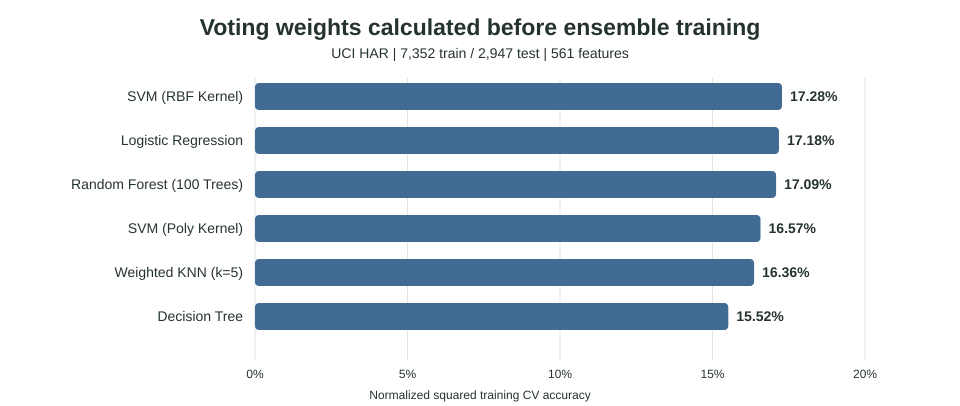

Held-out test accuracy — weighted-only ensemble
Weighted Soft Voting: 95.86%
Logistic Regression: 95.52%
SVM (RBF Kernel): 95.49%
Weighted Hard Voting: 95.08%
Random Forest (100 Trees): 92.67%
SVM (Poly Kernel): 92.40%
Weighted KNN (k=5): 88.43%
Decision Tree: 86.22%


In [2]:
base_models = {
    'SVM (RBF Kernel)': SVC(kernel='rbf', C=10.0, probability=True, random_state=42),
    'Logistic Regression': LogisticRegression(max_iter=2000, random_state=42),
    'Random Forest (100 Trees)': RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=1),
    'SVM (Poly Kernel)': SVC(kernel='poly', degree=3, C=1.0, probability=True, random_state=42),
    'Weighted KNN (k=5)': KNeighborsClassifier(n_neighbors=5, weights='distance'),
    'Decision Tree': DecisionTreeClassifier(random_state=42)
}

estimators = [(f'm{i+1:02d}', model) for i, model in enumerate(base_models.values())]

# Learn weights from training-only cross-validation (never the test set).
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
# Probability calibration is unnecessary for individual SVM accuracy in CV.
cv_scores = []
for _, model in estimators:
    cv_model = clone(model)
    if isinstance(cv_model, SVC):
        cv_model.set_params(probability=False)
    cv_scores.append(cross_val_score(make_pipeline(StandardScaler(), cv_model), X_train, y_train_enc, cv=cv, scoring='accuracy', n_jobs=1).mean())
cv_accuracy = np.array(cv_scores)
# Squaring accuracy gives stronger models greater influence while retaining all members.
weights = cv_accuracy ** 2
weights = weights / weights.sum()
weight_table = pd.DataFrame({'Model': list(base_models), 'CV Accuracy (%)': cv_accuracy * 100, 'Weight (%)': weights * 100})
print(weight_table.to_string(index=False))
fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.barh(weight_table['Model'], weight_table['Weight (%)'], color='#426b58', height=0.65)
ax.invert_yaxis()
ax.bar_label(bars, fmt='%.2f%%', padding=4)
ax.set_xlim(0, max(weight_table['Weight (%)']) * 1.25)
ax.set_xlabel('Normalized voting weight (%)')
ax.set_title('Training CV-based ensemble weights')
fig.tight_layout()
fig.savefig('../presentation/15_ensemble_weights.png', dpi=200, bbox_inches='tight')
fig.savefig('../presentation/ensemble_weighted_weights.svg', bbox_inches='tight')
plt.show()

# Weighted hard and soft voting
hard_voting = VotingClassifier(estimators=estimators, voting='hard', weights=weights)
soft_voting = VotingClassifier(estimators=estimators, voting='soft', weights=weights)

all_candidate_models = {**base_models, 'Weighted Hard Voting': hard_voting, 'Weighted Soft Voting': soft_voting}

print("Training all candidate models and ensembles on full training set...")
test_metrics = {}

for name, model in all_candidate_models.items():
    model.fit(X_train_scaled, y_train_enc)
    preds = model.predict(X_test_scaled)
    
    acc = accuracy_score(y_test_enc, preds)
    prec = precision_score(y_test_enc, preds, average='macro', zero_division=0)
    rec = recall_score(y_test_enc, preds, average='macro', zero_division=0)
    f1 = f1_score(y_test_enc, preds, average='macro', zero_division=0)
    
    test_metrics[name] = {
        'Accuracy (%)': round(acc * 100, 2),
        'Precision (%)': round(prec * 100, 2),
        'Recall (%)': round(rec * 100, 2),
        'F1-Score (%)': round(f1 * 100, 2)
    }
    print(f"{name:22s} -> Test Acc: {acc*100:.2f}% | F1: {f1*100:.2f}%")

final_comparison_table = pd.DataFrame(test_metrics).T.sort_values(by='Accuracy (%)', ascending=False)
print("\n" + "=" * 65)
print("FINAL TEST SET BENCHMARK REPORT (2,947 UNSEEN SAMPLES)")
print("=" * 65)
print(final_comparison_table)

print('scikit-learn version:', sklearn.__version__)
final_comparison_table.to_csv('../presentation/ensemble_test_results.csv')
weight_table.to_csv('../presentation/ensemble_weights.csv', index=False)


## 2️⃣ Performance Benchmark Visualization

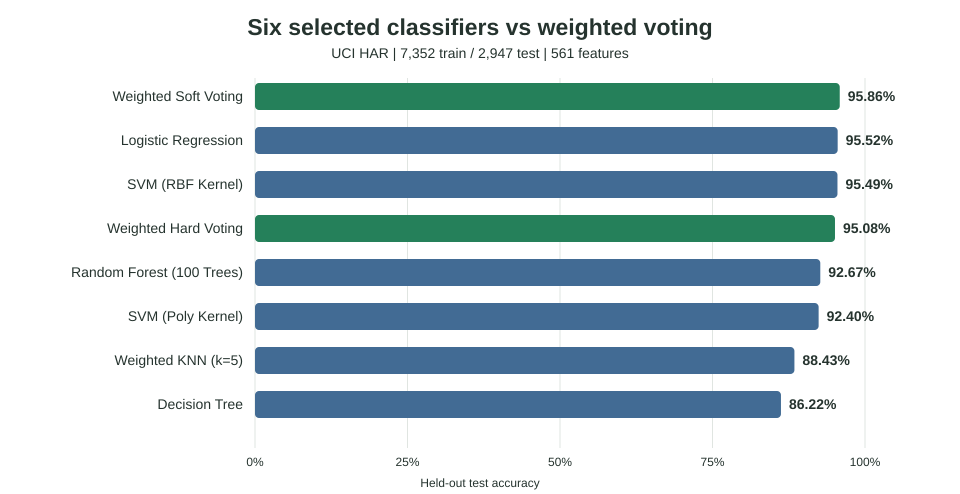

In [3]:
# Plot the current computed results only; no manually entered accuracy values.
fig, ax = plt.subplots(figsize=(10, 6), layout='constrained')
ordered = final_comparison_table.sort_values('Accuracy (%)')
colors = ['#25805a' if 'Voting' in name else '#426b94' for name in ordered.index]
bars = ax.barh(ordered.index, ordered['Accuracy (%)'], color=colors, height=0.68)
ax.bar_label(bars, fmt='%.2f%%', padding=5, fontsize=10)
ax.set_xlim(0, 110)
ax.set_xlabel('Held-out test accuracy (%)')
ax.set_title('Six classifiers vs accuracy-weighted hard and soft voting', fontweight='bold', pad=18)
fig.savefig('../presentation/13_final_ensemble_benchmark.png', dpi=200, bbox_inches='tight')
fig.savefig('../presentation/ensemble_weighted_benchmark.svg', bbox_inches='tight')
plt.show()


## 3️⃣ Detailed Classification Report for Champion Model

Local run champion: Weighted Soft Voting — 95.86% accuracy, 95.78% macro F1


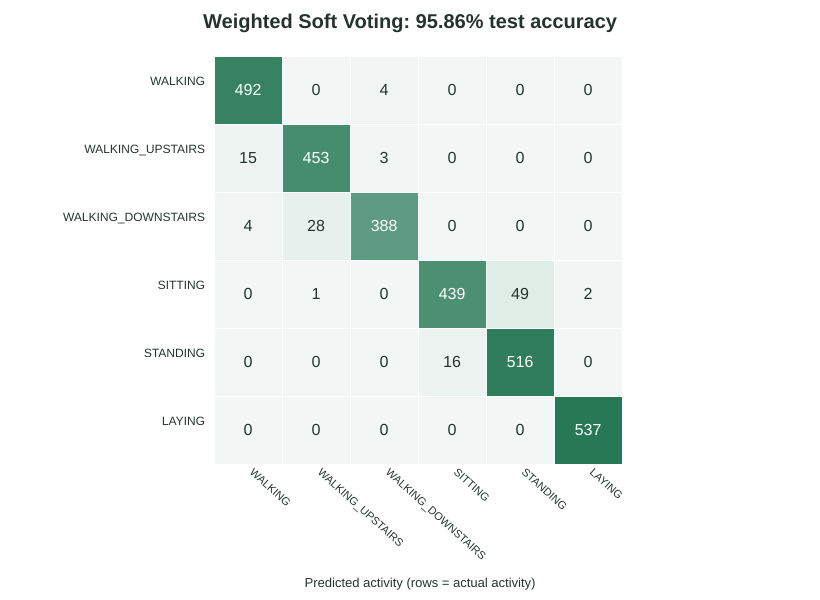

In [4]:
champion_name = final_comparison_table.index[0]
champion_model = all_candidate_models[champion_name]
y_champ_pred = champion_model.predict(X_test_scaled)

print(f"🏆 CHAMPION ARCHITECTURE: {champion_name}")
print(classification_report(y_test_enc, y_champ_pred, target_names=le.classes_))

# Confusion Matrix for Champion
cm = confusion_matrix(y_test_enc, y_champ_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Greens', cbar=False,
            xticklabels=le.classes_, yticklabels=le.classes_)
plt.title(f'Champion Model Confusion Matrix: {champion_name}', fontweight='bold')
plt.xlabel('Predicted Class', fontweight='bold')
plt.ylabel('Actual Class', fontweight='bold')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.savefig('../presentation/14_champion_confusion_matrix.png', dpi=200)
plt.savefig('../presentation/ensemble_weighted_champion.svg', bbox_inches='tight')
plt.show()

# Final Persistence for Streamlit & Demo Deployment
joblib.dump({
    'champion_model': champion_model,
    'champion_name': champion_name,
    'final_table': final_comparison_table,
    'scaler': scaler,
    'label_encoder': le,
    'models': all_candidate_models,
    'voting_weights': dict(zip(base_models, weights)),
    'weight_table': weight_table
}, '../models/final_evaluation_results.pkl')

print("✅ Pipeline complete! All artifacts saved to ../models/final_evaluation_results.pkl")